In [4]:
import os
import pandas
import numpy as np

current_dir = os.getcwd()

file_path = os.path.join(current_dir, "..", "..", "data", "heart.csv")

df = pandas.read_csv(file_path)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [2]:
print(f"\nA lots of data     : {df.shape[0]}")
print(f"\nDuplicate Data     : {df.duplicated().sum()}")
print(f"\nMissing value Data : \n{df.isnull().sum()}")


A lots of data     : 1025

Duplicate Data     : 723

Missing value Data : 
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.103240,-0.071966,0.271121,0.219823,0.121243,-0.132696,-0.390227,0.088163,0.208137,-0.169105,0.271551,0.072297,-0.229324
sex,-0.103240,1.000000,-0.041119,-0.078974,-0.198258,0.027200,-0.055117,-0.049365,0.139157,0.084687,-0.026666,0.111729,0.198424,-0.279501
cp,-0.071966,-0.041119,1.000000,0.038177,-0.081641,0.079294,0.043581,0.306839,-0.401513,-0.174733,0.131633,-0.176206,-0.163341,0.434854
trestbps,0.271121,-0.078974,0.038177,1.000000,0.127977,0.181767,-0.123794,-0.039264,0.061197,0.187434,-0.120445,0.104554,0.059276,-0.138772
chol,0.219823,-0.198258,-0.081641,0.127977,1.000000,0.026917,-0.147410,-0.021772,0.067382,0.064880,-0.014248,0.074259,0.100244,-0.099966
fbs,0.121243,0.027200,0.079294,0.181767,0.026917,1.000000,-0.104051,-0.008866,0.049261,0.010859,-0.061902,0.137156,-0.042177,-0.041164
restecg,-0.132696,-0.055117,0.043581,-0.123794,-0.147410,-0.104051,1.000000,0.048411,-0.065606,-0.050114,0.086086,-0.078072,-0.020504,0.134468
thalach,-0.390227,-0.049365,0.306839,-0.039264,-0.021772,-0.008866,0.048411,1.000000,-0.380281,-0.349796,0.395308,-0.207888,-0.098068,0.422895
exang,0.088163,0.139157,-0.401513,0.061197,0.067382,0.049261,-0.065606,-0.380281,1.000000,0.310844,-0.267335,0.107849,0.197201,-0.438029
oldpeak,0.208137,0.084687,-0.174733,0.187434,0.064880,0.010859,-0.050114,-0.349796,0.310844,1.000000,-0.575189,0.221816,0.202672,-0.438441


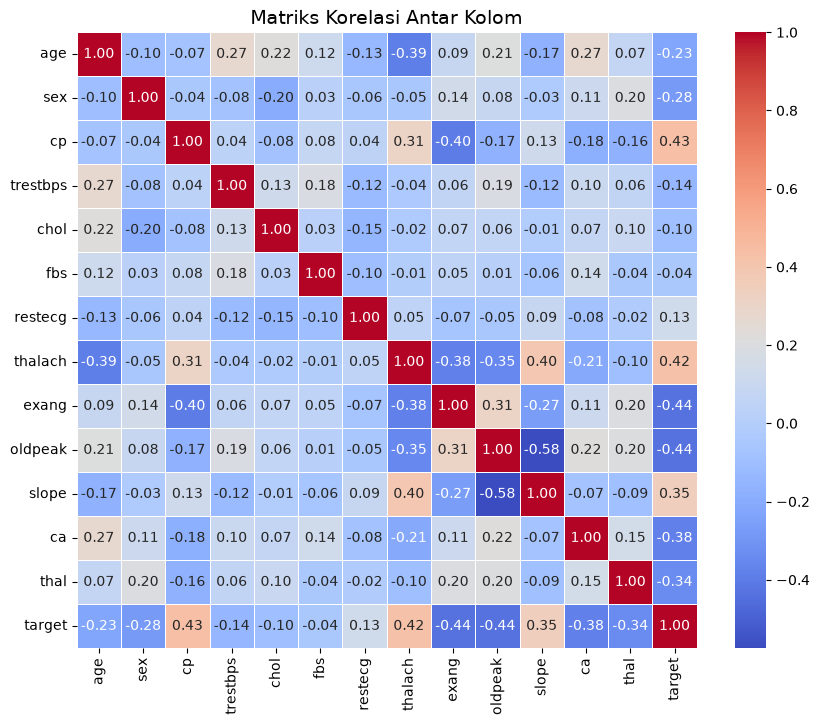

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Hitung matriks korelasi (khusus kolom numerik)
correlation_matrix = df.corr(numeric_only=True)

# Tampilkan angka korelasinya
display(correlation_matrix)

# 2. Visualisasikan menggunakan Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix, 
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title("Matriks Korelasi Antar Kolom", fontsize=14)
plt.show()

=== RINGKASAN DETEKSI OUTLIER ===


,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier,Persentase (%)
0,age,28.5,80.5,0,0.00
1,sex,-1.5,2.5,0,0.00
2,cp,-3.0,5.0,0,0.00
3,trestbps,90.0,170.0,30,2.93
4,chol,115.0,371.0,16,1.56
5,fbs,0.0,0.0,153,14.93
6,restecg,-1.5,2.5,0,0.00
7,thalach,81.0,217.0,4,0.39
8,exang,-1.5,2.5,0,0.00
9,oldpeak,-2.7,4.5,7,0.68


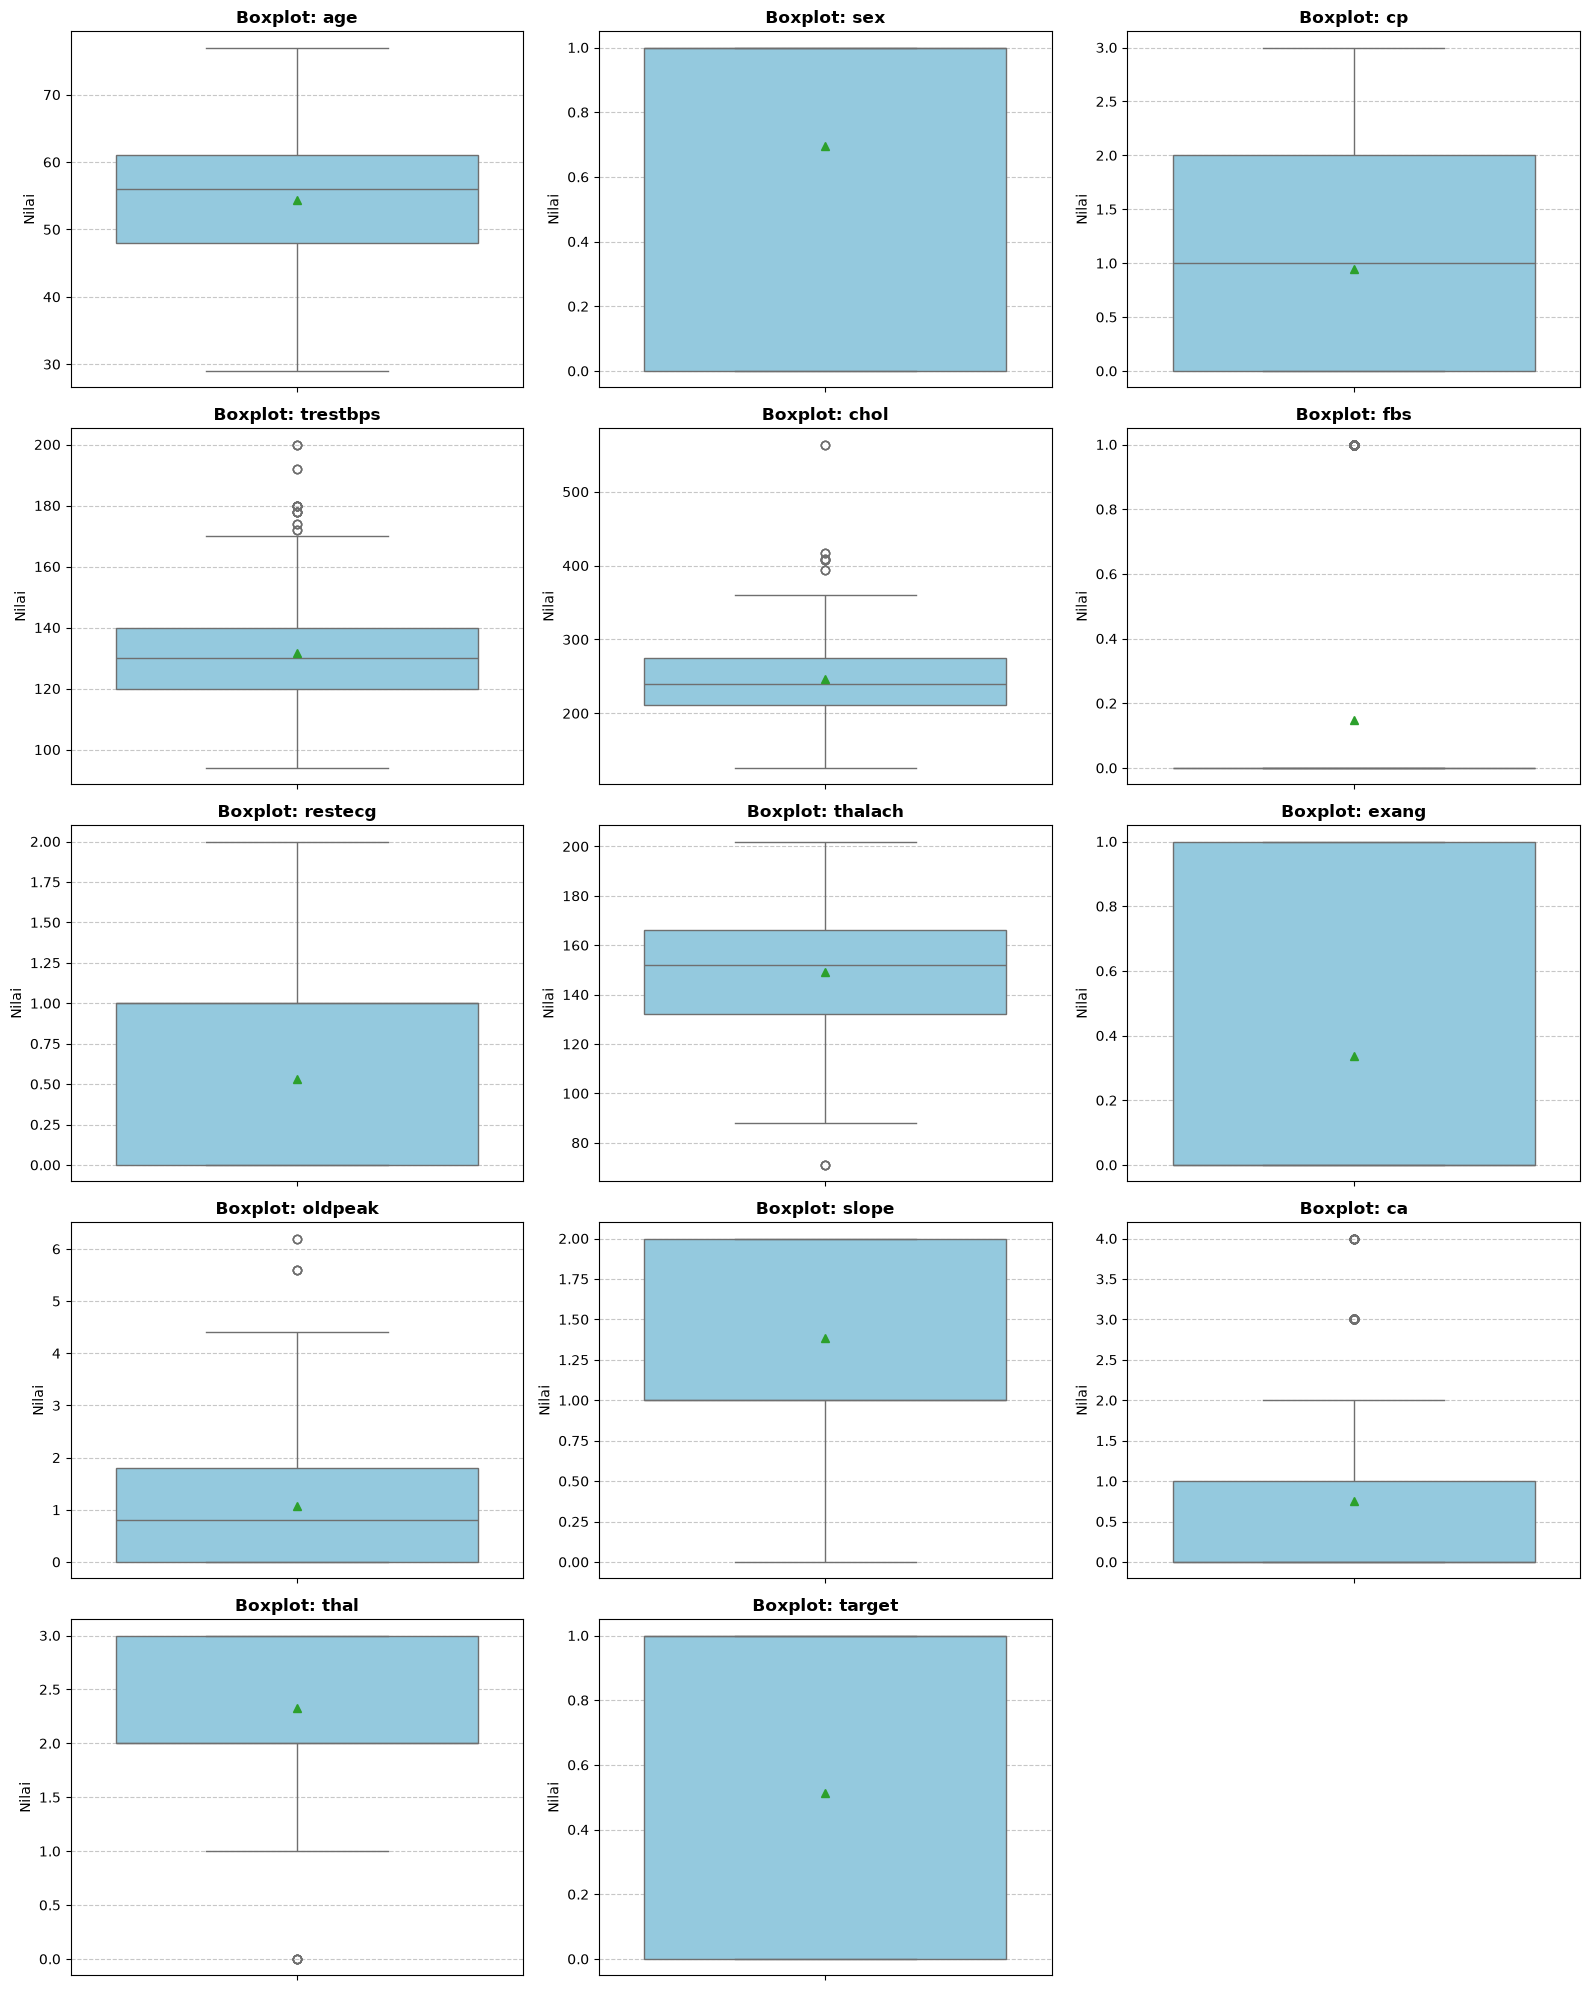

In [ ]:
numeric_cols = df.select_dtypes(include=[np.number]).columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = df[(df[col] < lower_bound) | (df[col] > upper_bound)].shape[0]
    percentage = (outlier_count / len(df)) * 100

    outlier_summary.append({
        'Kolom': col,
        'Batas Bawah': round(lower_bound, 2),
        'Batas Atas': round(upper_bound, 2),
        'Jumlah Outlier': outlier_count,
        'Persentase (%)': round(percentage, 2)
    })

outlier_df = pandas.DataFrame(outlier_summary)
print("=== RINGKASAN DETEKSI OUTLIER ===")
display(outlier_df)

n_cols = 3
n_rows = (len(numeric_cols) + n_cols - 1)

plt.figure(figsize=(16, 4 * n_rows))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.boxplot(y=df[col], color='skyblue', showmeans=True)
    plt.title(f'Boxplot: {col}', fontsize=12, fontweight='bold')
    plt.ylabel('Nilai')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()